# Standalone global H1–H12 price Extra Trees training

This Colab notebook uses the same data, chronological split, preprocessing, evaluation metrics, graphs, and output keys as the price XGBoost notebook. Extra Trees trains on CPU.

In [1]:
%pip install -q pandas scikit-learn==1.6.1 joblib==1.6.0 matplotlib seaborn

## Mount Google Drive and configure paths

Use the same `MyDrive/demand-forecasting/Dataset/price_horizon_training_dataset.csv` uploaded for XGBoost. Outputs are copied to `artifacts/price`.

In [2]:
import json
import platform
import shutil
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from google.colab import drive

drive.mount("/content/drive")

DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/demand-forecasting")
DRIVE_DATA_FILE = DRIVE_PROJECT_DIR / "Dataset" / "price_horizon_training_dataset.csv"
DRIVE_ARTIFACT_DIR = DRIVE_PROJECT_DIR / "artifacts" / "price"
LOCAL_ARTIFACT_DIR = Path("/content/price_etr_artifacts")

if not DRIVE_DATA_FILE.exists():
    raise FileNotFoundError(f"Upload price_horizon_training_dataset.csv to: {DRIVE_DATA_FILE}")

print(f"Dataset: {DRIVE_DATA_FILE}")
print(f"Local output: {LOCAL_ARTIFACT_DIR}")
print(f"Drive output: {DRIVE_ARTIFACT_DIR}")

Mounted at /content/drive
Dataset: /content/drive/MyDrive/demand-forecasting/Dataset/price_horizon_training_dataset.csv
Local output: /content/price_etr_artifacts
Drive output: /content/drive/MyDrive/demand-forecasting/artifacts/price


## Load data and create chronological splits

These boundaries are identical to price XGBoost: the newest three target months are test, the preceding three are validation, and all earlier months are training.

In [3]:
TARGET_COLUMN = "future_weighted_avg_procurement_price_rm_per_kg"
CATEGORICAL_FEATURES = ["crop", "location", "origin_season", "target_season"]
EXCLUDED_FEATURES = ["forecast_origin_month", "target_month", TARGET_COLUMN]
VALIDATION_MONTHS = 3
TEST_MONTHS = 3

data = pd.read_csv(DRIVE_DATA_FILE, parse_dates=["forecast_origin_month", "target_month"])
required = ["forecast_origin_month", "target_month", "forecast_horizon", *CATEGORICAL_FEATURES, TARGET_COLUMN]
missing = [column for column in required if column not in data.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")
if data[TARGET_COLUMN].isna().any():
    raise ValueError("Training data contains missing future price targets.")
if data.duplicated(["forecast_origin_month", "crop", "location", "forecast_horizon"]).any():
    raise ValueError("Training data contains duplicate horizon samples.")

data = data.sort_values(["target_month", "forecast_origin_month", "crop", "location"]).reset_index(drop=True)
final_month = data["target_month"].max().to_period("M").to_timestamp()
test_start = final_month - pd.DateOffset(months=TEST_MONTHS - 1)
validation_start = test_start - pd.DateOffset(months=VALIDATION_MONTHS)
train = data[data["target_month"] < validation_start].copy()
validation = data[data["target_month"].between(validation_start, test_start - pd.DateOffset(months=1))].copy()
test = data[data["target_month"] >= test_start].copy()

for name, split in {"train": train, "validation": validation, "test": test}.items():
    if split.empty:
        raise ValueError(f"{name} split is empty.")
    if set(split["forecast_horizon"].unique()) != set(range(1, 13)):
        raise ValueError(f"{name} split does not contain every H1–H12 horizon.")
if not (train["target_month"].max() < validation["target_month"].min() < test["target_month"].min()):
    raise ValueError("Chronological split boundaries overlap.")

print(f"Train: {len(train):,} rows, {train.target_month.min().date()} to {train.target_month.max().date()}")
print(f"Validation: {len(validation):,} rows, {validation.target_month.min().date()} to {validation.target_month.max().date()}")
print(f"Test: {len(test):,} rows, {test.target_month.min().date()} to {test.target_month.max().date()}")

Train: 19,170 rows, 2022-02-01 to 2025-06-01
Validation: 1,620 rows, 2025-07-01 to 2025-09-01
Test: 1,620 rows, 2025-10-01 to 2025-12-01


## Define preprocessing and Extra Trees

The preprocessing policy and feature columns match price XGBoost. Extra Trees uses CPU parallelism with `n_jobs=-1`; a Colab GPU does not accelerate this estimator.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

FEATURE_COLUMNS = [column for column in data.columns if column not in EXCLUDED_FEATURES]
NUMERIC_FEATURES = [column for column in FEATURE_COLUMNS if column not in CATEGORICAL_FEATURES]
unexpected_text = [column for column in NUMERIC_FEATURES if not pd.api.types.is_numeric_dtype(data[column])]
if unexpected_text:
    raise ValueError(f"Features need an explicit encoding policy: {unexpected_text}")

ETR_PARAMS = {
    "n_estimators": 500,
    "criterion": "squared_error",
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 2,
    "max_features": 0.8,
    "bootstrap": False,
    "random_state": 42,
    "n_jobs": -1,
}

def build_pipeline():
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    preprocessor = ColumnTransformer(
        [
            ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
            ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    model = ExtraTreesRegressor(**ETR_PARAMS)
    return Pipeline([("preprocessor", preprocessor), ("model", model)])

def split_xy(frame):
    return frame[FEATURE_COLUMNS].copy(), frame[TARGET_COLUMN].copy()

print(f"Features: {len(FEATURE_COLUMNS)} ({len(CATEGORICAL_FEATURES)} categorical, {len(NUMERIC_FEATURES)} numeric)")

Features: 73 (4 categorical, 69 numeric)


## Train, validate, refit, and test

The validation pipeline is fitted on training rows only. A fresh final pipeline is fitted on training plus validation rows before evaluating the untouched test period.

In [5]:
X_train, y_train = split_xy(train)
X_validation, y_validation = split_xy(validation)
X_test, y_test = split_xy(test)

validation_pipeline = build_pipeline()
validation_pipeline.fit(X_train, y_train)
validation_values = validation_pipeline.predict(X_validation)

train_validation = pd.concat([train, validation], ignore_index=True).sort_values("target_month")
X_train_validation, y_train_validation = split_xy(train_validation)
final_pipeline = build_pipeline()
final_pipeline.fit(X_train_validation, y_train_validation)
test_values = final_pipeline.predict(X_test)
print("Training complete.")

Training complete.


## Evaluate overall and by horizon

In [6]:
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

KEY_COLUMNS = ["forecast_origin_month", "target_month", "crop", "location", "forecast_horizon", TARGET_COLUMN]

def prediction_table(frame, values, split_name):
    output = frame[KEY_COLUMNS].copy()
    output["etr_prediction"] = values
    output["split"] = split_name
    output["absolute_error"] = (output[TARGET_COLUMN] - output["etr_prediction"]).abs()
    return output

def metric_values(frame):
    actual = frame[TARGET_COLUMN].to_numpy(dtype=float)
    predicted = frame["etr_prediction"].to_numpy(dtype=float)
    denominator = np.abs(actual).sum()
    return {
        "mae": mean_absolute_error(actual, predicted),
        "rmse": np.sqrt(mean_squared_error(actual, predicted)),
        "wape": np.abs(actual - predicted).sum() / denominator if denominator > 0 else np.nan,
        "r2": r2_score(actual, predicted),
    }

validation_predictions = prediction_table(validation, validation_values, "validation")
test_predictions = prediction_table(test, test_values, "test")
records = []
for split_name, predictions in [("validation", validation_predictions), ("test", test_predictions)]:
    records.append({"model": "extra_trees", "split": split_name, "forecast_horizon": "overall", "rows": len(predictions), **metric_values(predictions)})
    for horizon, group in predictions.groupby("forecast_horizon"):
        records.append({"model": "extra_trees", "split": split_name, "forecast_horizon": int(horizon), "rows": len(group), **metric_values(group)})

metrics = pd.DataFrame(records)
display(metrics)

,model,split,forecast_horizon,rows,mae,rmse,wape,r2
0,extra_trees,validation,overall,1620,0.139359,0.178828,0.032662,0.988829
1,extra_trees,validation,1,135,0.131448,0.174190,0.030808,0.989401
2,extra_trees,validation,2,135,0.129697,0.171277,0.030398,0.989753
3,extra_trees,validation,3,135,0.129416,0.170579,0.030332,0.989836
4,extra_trees,validation,4,135,0.128777,0.168682,0.030182,0.990061
5,extra_trees,validation,5,135,0.130525,0.170432,0.030592,0.989853
6,extra_trees,validation,6,135,0.133231,0.172789,0.031226,0.989571
7,extra_trees,validation,7,135,0.139129,0.177166,0.032608,0.989036
8,extra_trees,validation,8,135,0.147345,0.184099,0.034534,0.988161
9,extra_trees,validation,9,135,0.151813,0.188501,0.035581,0.987588


## Visualize model results

These are the same three diagnostic views used for price XGBoost.

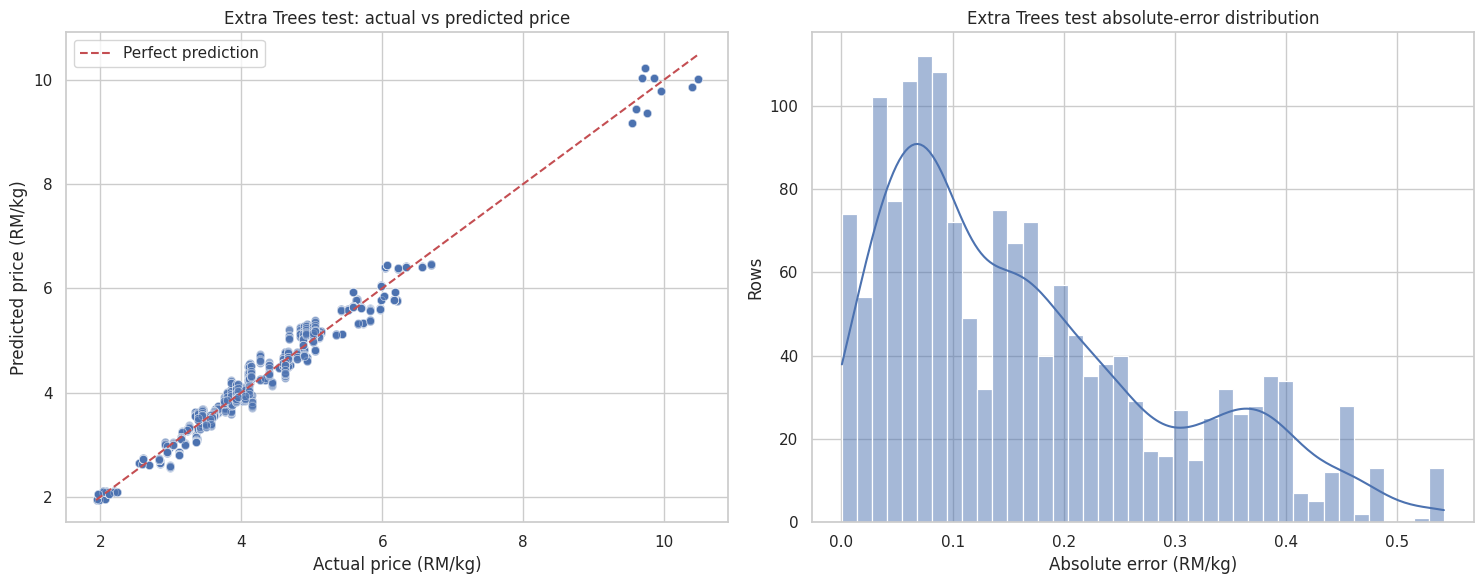

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=test_predictions, x=TARGET_COLUMN, y="etr_prediction", alpha=0.55, ax=axes[0])
minimum = min(test_predictions[TARGET_COLUMN].min(), test_predictions["etr_prediction"].min())
maximum = max(test_predictions[TARGET_COLUMN].max(), test_predictions["etr_prediction"].max())
axes[0].plot([minimum, maximum], [minimum, maximum], "r--", label="Perfect prediction")
axes[0].set_title("Extra Trees test: actual vs predicted price")
axes[0].set_xlabel("Actual price (RM/kg)")
axes[0].set_ylabel("Predicted price (RM/kg)")
axes[0].legend()
sns.histplot(test_predictions["absolute_error"], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Extra Trees test absolute-error distribution")
axes[1].set_xlabel("Absolute error (RM/kg)")
axes[1].set_ylabel("Rows")
plt.tight_layout()
plt.show()

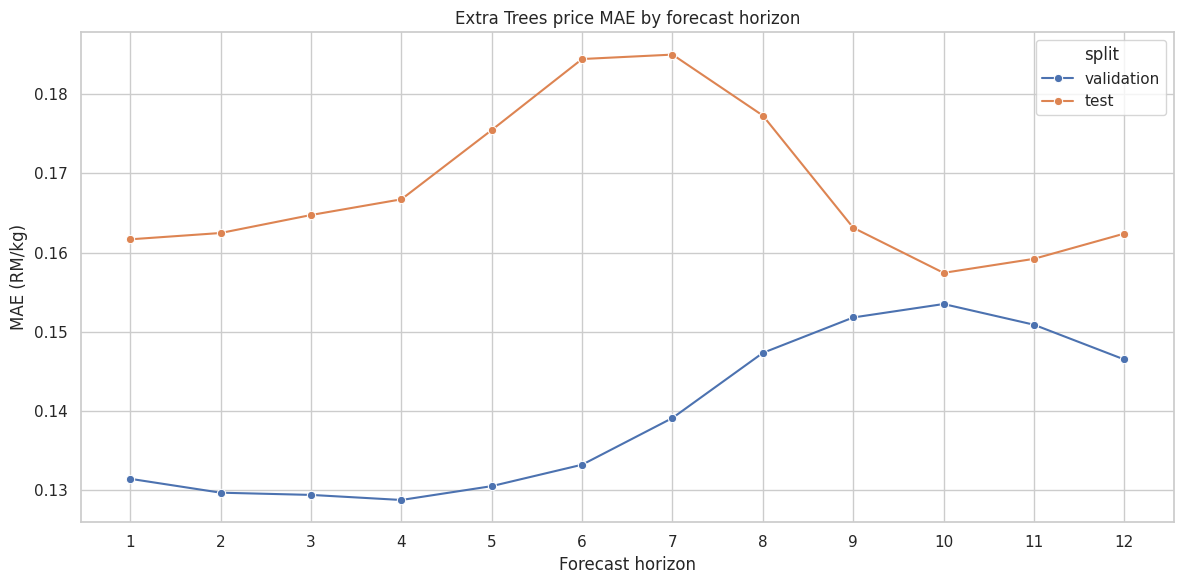

In [8]:
metrics_by_horizon = metrics[metrics["forecast_horizon"] != "overall"].copy()
metrics_by_horizon["forecast_horizon"] = metrics_by_horizon["forecast_horizon"].astype(int)
plt.figure(figsize=(12, 6))
sns.lineplot(data=metrics_by_horizon, x="forecast_horizon", y="mae", hue="split", marker="o")
plt.title("Extra Trees price MAE by forecast horizon")
plt.xlabel("Forecast horizon")
plt.ylabel("MAE (RM/kg)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

## Save locally and copy to Google Drive

Extra Trees has no separate native JSON format. The `.joblib` file contains the fitted preprocessing and regressor together.

In [9]:
local_model_dir = LOCAL_ARTIFACT_DIR / "models"
local_prediction_dir = LOCAL_ARTIFACT_DIR / "predictions"
local_report_dir = LOCAL_ARTIFACT_DIR / "reports"
for directory in [local_model_dir, local_prediction_dir, local_report_dir]:
    directory.mkdir(parents=True, exist_ok=True)

pipeline_file = local_model_dir / "global_etr_pipeline.joblib"
validation_file = local_prediction_dir / "etr_validation_predictions.csv"
test_file = local_prediction_dir / "etr_test_predictions.csv"
metrics_file = local_report_dir / "etr_metrics.csv"
metadata_file = local_report_dir / "etr_training_metadata.json"

joblib.dump(final_pipeline, pipeline_file)
validation_predictions.to_csv(validation_file, index=False)
test_predictions.to_csv(test_file, index=False)
metrics.to_csv(metrics_file, index=False)
metadata = {
    "model": "global_direct_multi_horizon_price_extra_trees",
    "target": TARGET_COLUMN,
    "feature_columns": FEATURE_COLUMNS,
    "categorical_features": CATEGORICAL_FEATURES,
    "extra_trees_parameters": ETR_PARAMS,
    "validation_months": VALIDATION_MONTHS,
    "test_months": TEST_MONTHS,
    "final_fit_data": "train + validation",
    "validation_prediction_model": "train only",
    "test_prediction_model": "train + validation",
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
}
metadata_file.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

local_files = [pipeline_file, validation_file, test_file, metrics_file, metadata_file]
for source in local_files:
    relative = source.relative_to(LOCAL_ARTIFACT_DIR)
    destination = DRIVE_ARTIFACT_DIR / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

print("Saved locally:")
for path in local_files:
    print(path)
print(f"\nCopied to Google Drive: {DRIVE_ARTIFACT_DIR}")

Saved locally:
/content/price_etr_artifacts/models/global_etr_pipeline.joblib
/content/price_etr_artifacts/predictions/etr_validation_predictions.csv
/content/price_etr_artifacts/predictions/etr_test_predictions.csv
/content/price_etr_artifacts/reports/etr_metrics.csv
/content/price_etr_artifacts/reports/etr_training_metadata.json

Copied to Google Drive: /content/drive/MyDrive/demand-forecasting/artifacts/price
